# Practical 9 - LBP and Denoising

Aim: Implement LBP and denoise Gaussian and speckle noise using Wiener, median, Gaussian and bilateral filters.

Name: Navjot Singh
Roll No: 2025010071


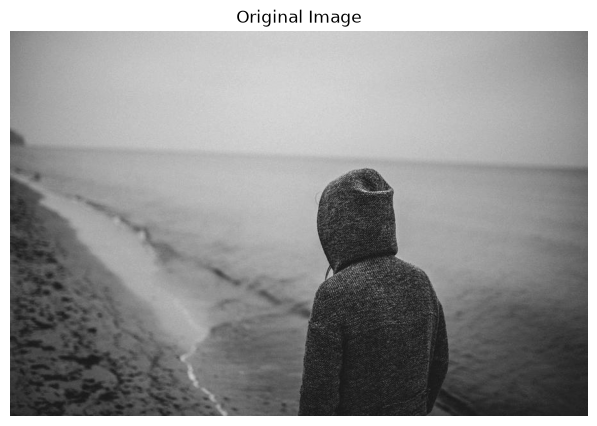

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

print("Name: Navjot Singh")
print("Roll No: 2025010071")

img = cv2.imread("images/navjot_b.jpg", cv2.IMREAD_GRAYSCALE)

plt.figure(figsize=(8, 5))
plt.imshow(img, cmap="gray")
plt.title("Original Image")
plt.axis("off")
plt.show()

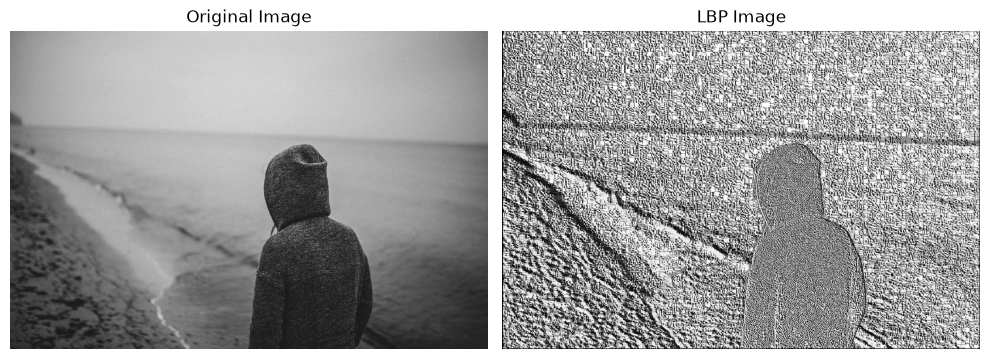

In [2]:
# LBP using 8 neighbours
lbp = np.zeros_like(img)

for i in range(1, img.shape[0] - 1):
    for j in range(1, img.shape[1] - 1):
        center = img[i, j]
        pixels = [
            img[i - 1, j - 1], img[i - 1, j], img[i - 1, j + 1],
            img[i, j + 1], img[i + 1, j + 1], img[i + 1, j],
            img[i + 1, j - 1], img[i, j - 1]
        ]
        value = 0
        for k in range(8):
            if pixels[k] >= center:
                value = value + 2 ** k
        lbp[i, j] = value

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.imshow(img, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(lbp, cmap="gray")
plt.title("LBP Image")
plt.axis("off")

plt.tight_layout()
plt.show()

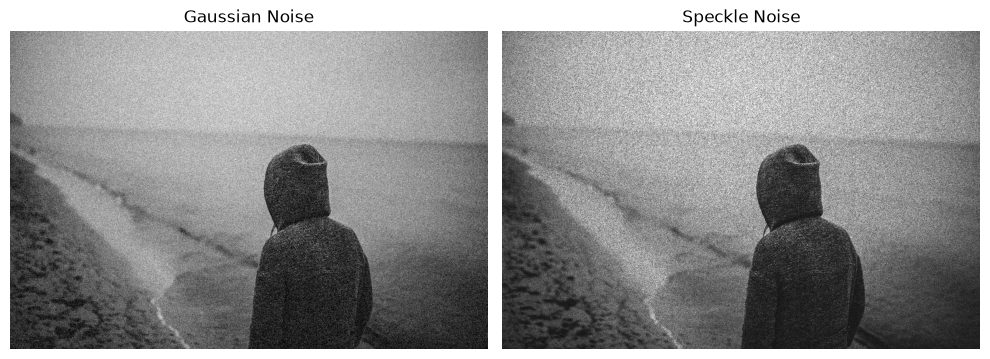

In [3]:
# add gaussian and speckle noise
gaussian_noise = img.astype(np.float32) + np.random.normal(0, 20, img.shape)
gaussian_noise = np.uint8(np.clip(gaussian_noise, 0, 255))

speckle_noise = img.astype(np.float32) + img.astype(np.float32) * np.random.normal(0, 0.2, img.shape)
speckle_noise = np.uint8(np.clip(speckle_noise, 0, 255))

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.imshow(gaussian_noise, cmap="gray")
plt.title("Gaussian Noise")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(speckle_noise, cmap="gray")
plt.title("Speckle Noise")
plt.axis("off")

plt.tight_layout()
plt.show()

In [4]:
# simple wiener filter
def wiener_filter(noisy):
    f = noisy.astype(np.float32)
    mean = cv2.blur(f, (5, 5))
    mean_square = cv2.blur(f * f, (5, 5))
    variance = np.maximum(mean_square - mean * mean, 0)
    noise_variance = np.mean(variance)
    result = mean + np.maximum(variance - noise_variance, 0) / (variance + 1e-6) * (f - mean)
    return np.uint8(np.clip(result, 0, 255))


def apply_filters(noisy):
    median = cv2.medianBlur(noisy, 3)
    gaussian = cv2.GaussianBlur(noisy, (3, 3), 0)
    bilateral = cv2.bilateralFilter(noisy, 5, 50, 50)
    wiener = wiener_filter(noisy)
    return [median, gaussian, bilateral, wiener]

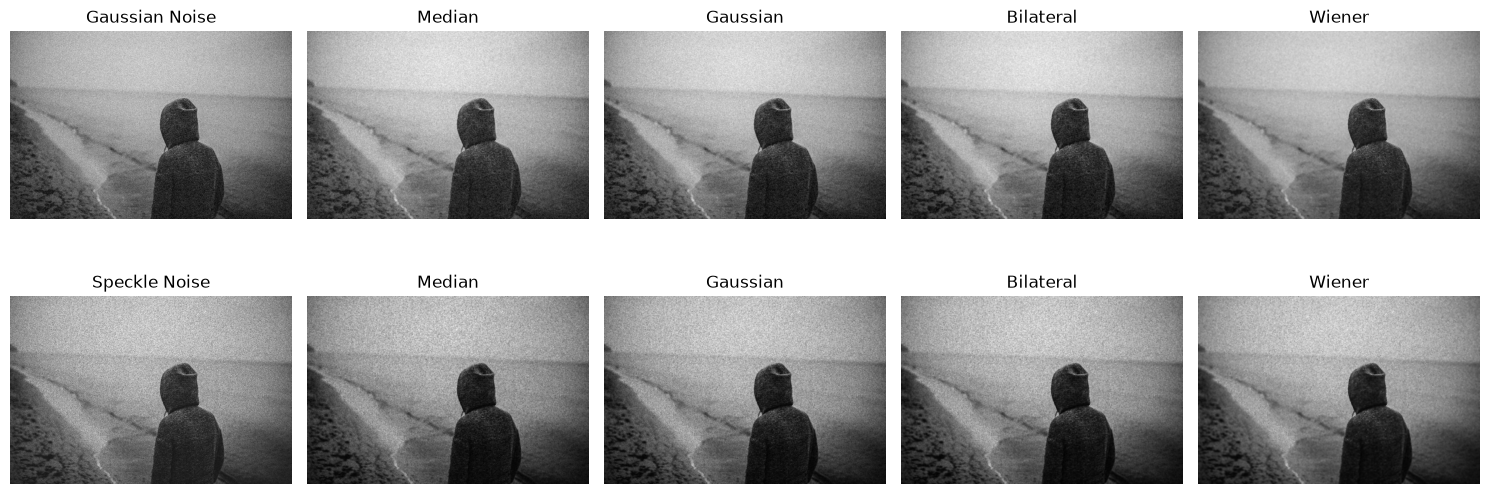

In [5]:
# apply all filters to both noisy images
gaussian_results = apply_filters(gaussian_noise)
speckle_results = apply_filters(speckle_noise)

filter_names = ["Median", "Gaussian", "Bilateral", "Wiener"]

plt.figure(figsize=(15, 6))

plt.subplot(2, 5, 1)
plt.imshow(gaussian_noise, cmap="gray")
plt.title("Gaussian Noise")
plt.axis("off")

for i in range(4):
    plt.subplot(2, 5, i + 2)
    plt.imshow(gaussian_results[i], cmap="gray")
    plt.title(filter_names[i])
    plt.axis("off")

plt.subplot(2, 5, 6)
plt.imshow(speckle_noise, cmap="gray")
plt.title("Speckle Noise")
plt.axis("off")

for i in range(4):
    plt.subplot(2, 5, i + 7)
    plt.imshow(speckle_results[i], cmap="gray")
    plt.title(filter_names[i])
    plt.axis("off")

plt.tight_layout()
plt.show()